# Évaluation de la classification IA des déviations

**Problème :** les 1 223 déviations qualité ne sont décrites qu'en texte libre. Sans catégorie de cause, impossible de savoir *pourquoi* un façonnier génère des déviations, ni d'orienter les audits.

**Solution testée :** un LLM (Google Gemini) classe chaque description dans une des 6 causes de la méthode des 6M (Matière, Méthode, Machine, Main-d'œuvre, Milieu, Mesure), via `src/classifier_deviations.py`. Les résultats sont enregistrés dans `data/processed/` : ce notebook ne rappelle **jamais** l'API et peut être réexécuté gratuitement.

**Évaluation :** on compare les catégories proposées par le LLM aux catégories réelles (table de vérité), puis on vérifie ce que la classification apporte au métier.

**Plan :** 1. Couverture · 2. Performance globale · 3. Matrice de confusion · 4. Comparaison avec les mots-clés · 5. Fiabilité de la confiance · 6. Analyse des erreurs · 7. Réponses métier · 8. Synthèse · 9. Export

In [53]:
import math
import re
import unicodedata
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import Markdown, display
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix, f1_score, precision_recall_fscore_support

RACINE = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
PROCESSED = RACINE / "data" / "processed"
VERITE = RACINE / "data" / "reference" / "verite"
FIGURES = RACINE / "docs" / "figures"
FIGURES.mkdir(parents=True, exist_ok=True)

CATEGORIES = ["Matière", "Méthode", "Machine", "Main-d'œuvre", "Milieu", "Mesure"]
ACCENT, CONTEXTE, ENCRE, GRILLE = "#2a78d6", "#a3a29d", "#52514e", "#e6e5e0"
plt.rcParams.update({
    "figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
    "axes.edgecolor": GRILLE, "axes.labelcolor": ENCRE, "xtick.color": ENCRE, "ytick.color": ENCRE,
    "axes.grid": True, "grid.color": GRILLE, "grid.linewidth": 0.8, "axes.axisbelow": True,
    "axes.titlesize": 12, "axes.titleweight": "bold", "axes.titlelocation": "left",
})


def pct(x, d=0):
    return f"{x:.{d}%}".replace(".", ",")


def test_deux_proportions(succes_a, n_a, succes_b, n_b):
    p = (succes_a + succes_b) / (n_a + n_b)
    se = math.sqrt(p * (1 - p) * (1 / n_a + 1 / n_b))
    z = (succes_a / n_a - succes_b / n_b) / se if se > 0 else 0.0
    return z, math.erfc(abs(z) / math.sqrt(2))


def formater_p(p):
    return "< 0,001" if p < 0.001 else f"{p:.3f}".replace(".", ",")


def enregistrer(fig, nom):
    fig.savefig(FIGURES / f"{nom}.png", bbox_inches="tight", dpi=150)

In [54]:
deviations = pd.read_csv(PROCESSED / "fact_deviation.csv")
lots = pd.read_csv(PROCESSED / "fact_lot.csv")[["id_lot", "taille_lot"]]
verite = pd.read_csv(VERITE / "fact_deviation.csv")[["id_deviation", "categorie_6m_verite"]]

base = (deviations.merge(lots, on="id_lot", how="left")
                  .merge(verite, on="id_deviation", how="left"))
base["gros_lot"] = base["taille_lot"] > 50_000

# Résultats du LLM, par mode (le few-shot est facultatif)
resultats = {}
for mode in ["zero_shot", "few_shot"]:
    fichier = PROCESSED / f"deviations_classees_{mode}.csv"
    if fichier.exists():
        resultats[mode] = pd.read_csv(fichier)

if not resultats:
    raise FileNotFoundError("Aucun résultat : lance d'abord  python src/classifier_deviations.py")

# Les exemples montrés au modèle en few-shot sont exclus de TOUTES les évaluations (comparaison équitable)
fichier_exemples = PROCESSED / "exemples_few_shot.csv"
ids_exemples = set(pd.read_csv(fichier_exemples)["id_deviation"]) if fichier_exemples.exists() else set()
evaluees = base[~base["id_deviation"].isin(ids_exemples)].copy()

for mode, df in resultats.items():
    evaluees = evaluees.merge(
        df[["id_deviation", "categorie_ia", "confiance", "justification"]]
          .rename(columns=lambda c: c if c == "id_deviation" else f"{c}_{mode}"),
        on="id_deviation", how="left")

print(f"Déviations : {len(base)} | exemples few-shot exclus : {len(ids_exemples)} | évaluées : {len(evaluees)}")
print("Modes disponibles :", ", ".join(resultats))

Déviations : 1223 | exemples few-shot exclus : 12 | évaluées : 1211
Modes disponibles : zero_shot, few_shot


## 1. Couverture

Toutes les déviations ont-elles reçu une réponse valide du modèle ?

In [55]:
couverture = pd.DataFrame({
    mode: {
        "modèle": df["modele"].iloc[0],
        "déviations classées": f"{evaluees[f'categorie_ia_{mode}'].notna().sum()} / {len(evaluees)}",
        "confiance haute": pct(df["confiance"].eq("haute").mean()),
        "confiance moyenne": pct(df["confiance"].eq("moyenne").mean()),
        "confiance basse": pct(df["confiance"].eq("basse").mean()),
    }
    for mode, df in resultats.items()
})
couverture

,zero_shot,few_shot
modèle,gemini-flash-latest,gemini-flash-latest
déviations classées,1211 / 1211,1211 / 1211
confiance haute,100%,100%
confiance moyenne,0%,0%
confiance basse,0%,0%


## 2. Performance globale

- **Exactitude** (*accuracy*) : part des déviations bien classées.
- **F1 macro** : moyenne des F1 des 6 catégories, sans pondération. Une catégorie rare mal reconnue (Milieu, Mesure) fait baisser ce score, alors qu'elle passerait inaperçue dans l'exactitude.
- **Référence naïve** : toujours répondre la catégorie la plus fréquente. Un modèle utile doit faire beaucoup mieux.

In [56]:
def evaluer(mode):
    ok = evaluees[f"categorie_ia_{mode}"].notna()
    y_vrai, y_pred = evaluees.loc[ok, "categorie_6m_verite"], evaluees.loc[ok, f"categorie_ia_{mode}"]
    return {"exactitude": accuracy_score(y_vrai, y_pred),
            "F1 macro": f1_score(y_vrai, y_pred, average="macro", labels=CATEGORIES),
            "déviations évaluées": int(ok.sum())}

performance = pd.DataFrame({mode: evaluer(mode) for mode in resultats}).T
plus_frequente = evaluees["categorie_6m_verite"].value_counts(normalize=True)
performance.loc["référence naïve (toujours « " + plus_frequente.index[0] + " »)"] = \
    [plus_frequente.iloc[0], np.nan, len(evaluees)]

meilleur = performance.drop(index=[i for i in performance.index if i.startswith("référence")])["exactitude"].idxmax()
col_pred = f"categorie_ia_{meilleur}"
print(f"Meilleur mode : {meilleur}")
performance.style.format({"exactitude": "{:.1%}", "F1 macro": "{:.1%}", "déviations évaluées": "{:.0f}"}, na_rep="—")

Meilleur mode : few_shot


,exactitude,F1 macro,déviations évaluées
zero_shot,99.8%,99.7%,1211
few_shot,99.9%,99.9%,1211
référence naïve (toujours « Matière »),33.7%,—,1211


In [57]:
ok = evaluees[col_pred].notna()
rapport = pd.DataFrame(classification_report(evaluees.loc[ok, "categorie_6m_verite"], evaluees.loc[ok, col_pred],
                                             labels=CATEGORIES, output_dict=True, zero_division=0)).T
rapport = rapport.loc[CATEGORIES, ["precision", "recall", "f1-score", "support"]]
rapport.columns = ["précision", "rappel", "F1", "nombre réel"]
print("Précision : quand le modèle dit « X », a-t-il raison ?  |  Rappel : parmi les vrais « X », combien en trouve-t-il ?")
rapport.style.format({"précision": "{:.1%}", "rappel": "{:.1%}", "F1": "{:.1%}", "nombre réel": "{:.0f}"}) \
       .background_gradient(subset=["F1"], cmap="Blues", vmin=0.5, vmax=1)

Précision : quand le modèle dit « X », a-t-il raison ?  |  Rappel : parmi les vrais « X », combien en trouve-t-il ?


,précision,rappel,F1,nombre réel
Matière,100.0%,100.0%,100.0%,408
Méthode,99.6%,100.0%,99.8%,274
Machine,100.0%,100.0%,100.0%,191
Main-d'œuvre,100.0%,99.4%,99.7%,157
Milieu,100.0%,100.0%,100.0%,88
Mesure,100.0%,100.0%,100.0%,93


## 3. Matrice de confusion

Chaque ligne est une catégorie réelle et se lit en pourcentage : la diagonale indique ce qui est bien classé, le reste montre **avec quoi** le modèle confond.

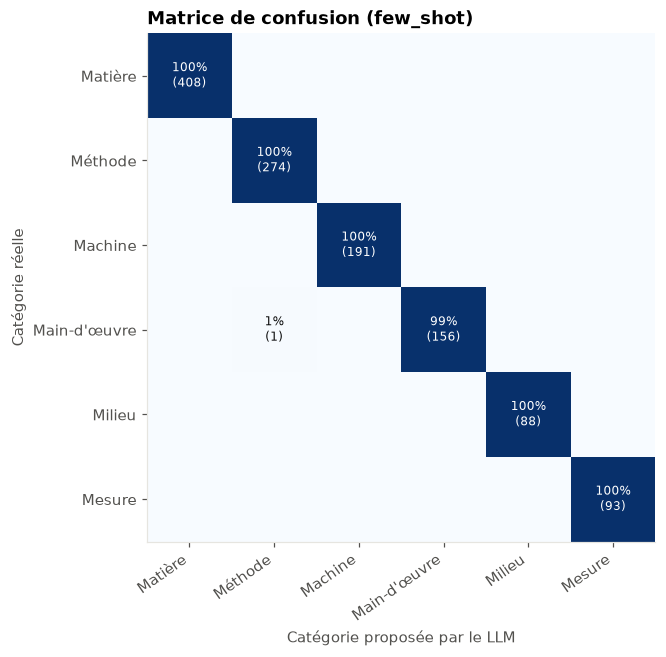

In [58]:
cm = confusion_matrix(evaluees.loc[ok, "categorie_6m_verite"], evaluees.loc[ok, col_pred], labels=CATEGORIES)
cm_pct = cm / cm.sum(axis=1, keepdims=True)

fig, ax = plt.subplots(figsize=(7.5, 6))
im = ax.imshow(cm_pct, cmap="Blues", vmin=0, vmax=1)
ax.set_xticks(range(6), CATEGORIES, rotation=35, ha="right")
ax.set_yticks(range(6), CATEGORIES)
ax.set_xlabel("Catégorie proposée par le LLM")
ax.set_ylabel("Catégorie réelle")
ax.grid(False)
for i in range(6):
    for j in range(6):
        if cm[i, j]:
            ax.text(j, i, f"{cm_pct[i, j]:.0%}\n({cm[i, j]})", ha="center", va="center", fontsize=8,
                    color="white" if cm_pct[i, j] > 0.6 else "#0b0b0b")
ax.set_title(f"Matrice de confusion ({meilleur})")
enregistrer(fig, "06_matrice_confusion_ia")
plt.show()

## 4. Le LLM fait-il mieux que les mots-clés ?

En phase 3, on avait repéré les déviations « Matière » par une simple liste de mots-clés. On compare les deux approches sur cette même question : *la déviation est-elle liée à la matière ?*

In [59]:
def normaliser(texte):
    texte = unicodedata.normalize("NFKD", str(texte).lower())
    return "".join(c for c in texte if not unicodedata.combining(c))

MOTS_MATIERE = r"matiere premiere|\bmp\b|excipient|fournisseur|\bfut\b|conditionnement|quarantaine|certificat"
evaluees["mots_matiere"] = evaluees["description_libre"].map(normaliser).str.contains(MOTS_MATIERE, regex=True)

vrai_matiere = evaluees.loc[ok, "categorie_6m_verite"].eq("Matière")
lignes = {}
for nom, pred in {"Mots-clés (phase 3)": evaluees.loc[ok, "mots_matiere"],
                  f"LLM ({meilleur})": evaluees.loc[ok, col_pred].eq("Matière")}.items():
    p, r, f, _ = precision_recall_fscore_support(vrai_matiere, pred, average="binary", zero_division=0)
    lignes[nom] = {"précision": p, "rappel": r, "F1": f, "fausses alertes": int((pred & ~vrai_matiere).sum())}
comparaison = pd.DataFrame(lignes).T
comparaison.style.format({"précision": "{:.1%}", "rappel": "{:.1%}", "F1": "{:.1%}", "fausses alertes": "{:.0f}"})

,précision,rappel,F1,fausses alertes
Mots-clés (phase 3),75.5%,82.4%,78.8%,109
LLM (few_shot),100.0%,100.0%,100.0%,0


**Pourquoi les mots-clés se trompent :** « quarantaine » ou « fournisseur » apparaissent aussi dans les phrases de suivi (« Lot placé en quarantaine ») de déviations qui n'ont rien à voir avec la matière, et les fautes de frappe ou abréviations font rater de vraies déviations Matière. Un LLM lit la phrase entière et peut distinguer la cause de la suite donnée : le tableau ci-dessus dit s'il y parvient vraiment.

## 5. La confiance annoncée par le modèle est-elle fiable ?

Si le modèle dit « confiance basse », se trompe-t-il vraiment plus souvent ? Si oui, on peut envoyer **seulement** ces cas à une relecture humaine.

In [60]:
conf = evaluees.loc[ok].assign(correct=lambda d: d[col_pred].eq(d["categorie_6m_verite"]))
fiabilite = conf.groupby(f"confiance_{meilleur}").agg(deviations=("correct", "size"), exactitude=("correct", "mean"))
fiabilite = fiabilite.reindex([c for c in ["haute", "moyenne", "basse"] if c in fiabilite.index])
fiabilite["part du total"] = fiabilite["deviations"] / fiabilite["deviations"].sum()
fiabilite.style.format({"exactitude": "{:.1%}", "part du total": "{:.1%}"})

,deviations,exactitude,part du total
confiance_few_shot,,,
haute,1209,100.0%,99.8%
moyenne,2,50.0%,0.2%


## 6. Analyse des erreurs

Quelles confusions sont les plus fréquentes, et sur quelles descriptions ?

In [61]:
erreurs = conf[~conf["correct"]]
paires = (erreurs.groupby(["categorie_6m_verite", col_pred]).size()
                 .sort_values(ascending=False).head(6).rename("nombre").reset_index())
paires.columns = ["catégorie réelle", "proposée par le LLM", "nombre"]
print(f"{len(erreurs)} erreurs sur {len(conf)} déviations ({pct(len(erreurs) / len(conf), 1)})")
display(paires)

exemples_erreurs = erreurs[["description_libre", "categorie_6m_verite", col_pred, f"justification_{meilleur}"]] \
    .sample(min(10, len(erreurs)), random_state=1)
exemples_erreurs.columns = ["description", "réelle", "LLM", "justification du LLM"]
pd.set_option("display.max_colwidth", 120)
exemples_erreurs

1 erreurs sur 1211 déviations (0,1%)


,catégorie réelle,proposée par le LLM,nombre
0,Main-d'œuvre,Méthode,1


,description,réelle,LLM,justification du LLM
957,Port des équipements de protection non conforme en zone de fabrication. Investigation ouverte,Main-d'œuvre,Méthode,Non-respect des règles de port d'EPI.


**À regarder dans ces exemples :** les erreurs portent-elles sur des descriptions qui mêlent deux causes (par exemple une erreur d'opérateur sur une matière première, ou un indice ajouté comme « constaté par l'opé ») ? Dans ces cas, même deux experts qualité pourraient hésiter : c'est la limite d'une description courte en texte libre. Note tes propres observations ici, elles sont précieuses en entretien.

## 7. Réponses métier

La classification permet enfin de répondre aux deux questions laissées ouvertes en phase 3. On compare les conclusions obtenues avec les catégories du LLM à celles obtenues avec les vraies catégories : **un modèle utile doit mener aux mêmes décisions.**

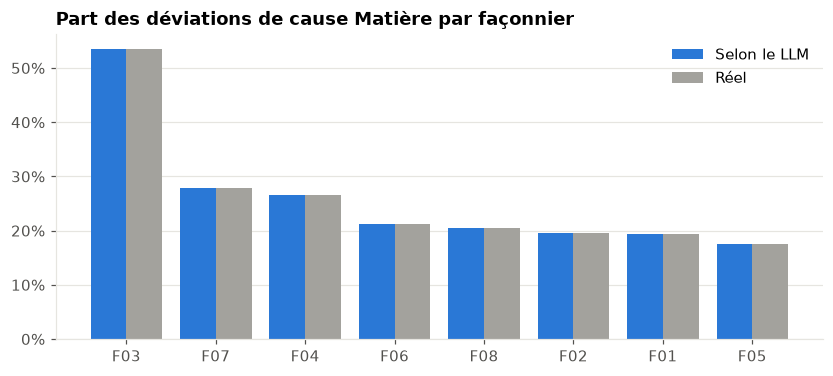

,Matière selon le LLM,Matière réelle,déviations
id_facconnier,,,
F03,54%,54%,433
F07,28%,28%,108
F04,27%,27%,207
F06,21%,21%,66
F08,21%,21%,107
F02,20%,20%,138
F01,19%,19%,67
F05,18%,18%,97


In [62]:
toutes = base.merge(resultats[meilleur][["id_deviation", "categorie_ia"]], on="id_deviation", how="left")

matiere = pd.DataFrame({
    "Matière selon le LLM": toutes.groupby("id_facconnier")["categorie_ia"].apply(lambda s: s.eq("Matière").mean()),
    "Matière réelle": toutes.groupby("id_facconnier")["categorie_6m_verite"].apply(lambda s: s.eq("Matière").mean()),
    "déviations": toutes.groupby("id_facconnier").size(),
}).sort_values("Matière selon le LLM", ascending=False)
f_matiere = matiere.index[0]

fig, ax = plt.subplots(figsize=(9, 3.6))
x = np.arange(len(matiere))
ax.bar(x - 0.2, matiere["Matière selon le LLM"], width=0.4, color=ACCENT, label="Selon le LLM")
ax.bar(x + 0.2, matiere["Matière réelle"], width=0.4, color=CONTEXTE, label="Réel")
ax.set_xticks(x, matiere.index)
ax.yaxis.set_major_formatter(lambda v, _: f"{v:.0%}")
ax.grid(axis="x", visible=False)
ax.legend(frameon=False)
ax.set_title("Part des déviations de cause Matière par façonnier")
enregistrer(fig, "07_matiere_par_facconnier_ia")
plt.show()
matiere.style.format({"Matière selon le LLM": "{:.0%}", "Matière réelle": "{:.0%}"})

In [63]:
lignes = []
for source, col in [("LLM", "categorie_ia"), ("réel", "categorie_6m_verite")]:
    gros, autres = toutes[toutes["gros_lot"]], toutes[~toutes["gros_lot"]]
    z, p = test_deux_proportions(gros[col].eq("Méthode").sum(), len(gros), autres[col].eq("Méthode").sum(), len(autres))
    lignes.append({"source": source, "Méthode, lots > 50 000": gros[col].eq("Méthode").mean(),
                   "Méthode, autres lots": autres[col].eq("Méthode").mean(), "p-value": p})
methode = pd.DataFrame(lignes).set_index("source")
methode.style.format({"Méthode, lots > 50 000": "{:.0%}", "Méthode, autres lots": "{:.0%}", "p-value": formater_p})

,"Méthode, lots > 50 000","Méthode, autres lots",p-value
source,,,
LLM,35%,21%,"< 0,001"
réel,35%,21%,"< 0,001"


## 8. Synthèse

Les constats ci-dessous sont générés à partir des résultats, pour rester justes si la classification est relancée.

In [64]:
perf = performance.loc[meilleur]
m_llm = methode.loc["LLM"]
lignes_synthese = [
    f"1. **Le LLM classe correctement {pct(perf['exactitude'], 1)} des déviations** ({meilleur.replace('_', '-')}, "
    f"F1 macro {pct(perf['F1 macro'], 1)}), contre {pct(plus_frequente.iloc[0], 1)} pour une réponse naïve.",
    f"2. **Il fait mieux que les mots-clés** pour repérer les causes Matière : F1 de "
    f"{pct(comparaison.iloc[1]['F1'])} contre {pct(comparaison.iloc[0]['F1'])}, avec "
    f"{int(comparaison.iloc[1]['fausses alertes'])} fausses alertes au lieu de {int(comparaison.iloc[0]['fausses alertes'])}.",
    f"3. **{f_matiere} concentre les déviations Matière** : {pct(matiere.loc[f_matiere, 'Matière selon le LLM'])} "
    f"selon le LLM ({pct(matiere.loc[f_matiere, 'Matière réelle'])} en réalité). "
    "→ Recommandation : audit de la réception et du contrôle des matières premières chez ce façonnier.",
    f"4. **Les gros lots (> 50 000 unités) ont davantage de déviations de Méthode** : "
    f"{pct(m_llm['Méthode, lots > 50 000'])} contre {pct(m_llm['Méthode, autres lots'])} (p-value {formater_p(m_llm['p-value'])}). "
    "→ Recommandation : revoir les instructions de fabrication pour les grands volumes (temps de mélange, ordre des phases).",
]
if len(resultats) > 1:
    gain = performance.loc["few_shot", "exactitude"] - performance.loc["zero_shot", "exactitude"]
    gain_txt = f"{gain * 100:+.1f}".replace(".", ",")
    lignes_synthese.append(
        f"5. **Montrer 12 exemples annotés au modèle (few-shot)** change l'exactitude de {gain_txt} points.")
Markdown("\n\n".join(lignes_synthese))

1. **Le LLM classe correctement 99,9% des déviations** (few-shot, F1 macro 99,9%), contre 33,7% pour une réponse naïve.

2. **Il fait mieux que les mots-clés** pour repérer les causes Matière : F1 de 100% contre 79%, avec 0 fausses alertes au lieu de 109.

3. **F03 concentre les déviations Matière** : 54% selon le LLM (54% en réalité). → Recommandation : audit de la réception et du contrôle des matières premières chez ce façonnier.

4. **Les gros lots (> 50 000 unités) ont davantage de déviations de Méthode** : 35% contre 21% (p-value < 0,001). → Recommandation : revoir les instructions de fabrication pour les grands volumes (temps de mélange, ordre des phases).

5. **Montrer 12 exemples annotés au modèle (few-shot)** change l'exactitude de +0,2 points.

## 9. Export pour Power BI

Une table des déviations enrichie de la catégorie proposée par le LLM, de la confiance et de la taille du lot.

In [65]:
export = base.merge(resultats[meilleur][["id_deviation", "categorie_ia", "confiance", "justification"]],
                    on="id_deviation", how="left")
colonnes = ["id_deviation", "id_lot", "id_commande", "id_facconnier", "sku", "date_ouverture", "date_cloture",
            "statut_deviation", "gravite", "description_libre", "delai_cloture_jours", "cloture_30j",
            "taille_lot", "gros_lot", "categorie_ia", "confiance", "justification"]
export[colonnes].to_csv(PROCESSED / "analyse_deviations.csv", index=False, encoding="utf-8")
print(f"analyse_deviations.csv : {len(export)} lignes, catégorie IA du mode {meilleur}")

analyse_deviations.csv : 1223 lignes, catégorie IA du mode few_shot


## Ce que je retiens

- Un LLM se **mesure** comme n'importe quel modèle : jeu de référence, exactitude, F1 par classe, matrice de confusion et analyse des erreurs.
- La **confiance annoncée** sert à décider quand l'humain doit relire : l'IA trie, l'expert valide les cas douteux.
- Les résultats sont **sauvegardés** : l'analyse est reproductible sans rappeler l'API, et le coût reste maîtrisé.
- Le vrai test est métier : la classification IA mène-t-elle **aux mêmes décisions** que les vraies catégories ?
- Sur des données réelles de santé, il faudrait une offre d'API qui n'utilise pas les données pour l'entraînement, ou un modèle hébergé en interne.